## Building a Language Detector

**Author:** Diego Besada

Created using [Pierre Nugues' template](https://github.com/pnugues/edan20/blob/master/labs_2026/4-language_detector_pytorch.ipynb)

Dataset: [Sentences Tatoeba](https://downloads.tatoeba.org/exports/sentences.tar.bz2)

## Objectives

We implement a simplified version of Google's *Compact Language Detector* (CLD3),
https://github.com/google/cld3. CLD3 classifies a text with a feed-forward network
whose input is the vector of relative frequencies of the character $n$-grams of the
text. As $n$-grams form an open set, they are mapped onto a fixed-size vector with
the *hashing trick*.

The outline of the notebook is:

1. Count the $n$-grams of the whole corpus and study the hash collisions;
2. Build the feature matrix $X$ and the label vector $\mathbf{y}$, and train a classifier with the scikit-learn API;
3. Reimplement the same classifier with PyTorch, writing the gradient descent loop explicitly;
4. Evaluate and compare both models.

In [1]:
import random, joblib, torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from collections import Counter
from collections.abc import Iterator
from hashlib import md5

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import warnings
warnings.filterwarnings('ignore')

random.seed(4321)
np.random.seed(4321)
torch.manual_seed(4321);

## 1. The dataset and its $n$-grams

We use [Tatoeba](https://tatoeba.org/eng/downloads), a collection of more than 13
million short sentences in over 400 languages. Each line of `sentences.csv` has three
tab-separated fields:

```
sentence id [tab] language code [tab] text [cr]
```

The language codes follow the ISO 639-3 standard. We read the file with a generator
so that we never load the 758 MB corpus in memory.

In [2]:
FILE = 'sentences.csv'

def file_reader(file) -> Iterator[tuple[str, str, str]]:
    '''
    Every line is:
    N (tab) language (tab) sentence
    where N is a number, language is a string, and sentence is a string.
    Returns a generator of tuples (N, language, sentence).
    '''

    with open(file, encoding='utf8', errors='ignore') as f:
        for line in f:
            row = line.strip()
            yield tuple(row.split('\t'))

#### Counting the languages

We count the sentences per language to know the size of each class. `langs` holds
every language code present in the corpus.

In [3]:
lang_freqs = Counter(map(lambda x: x[1], file_reader(FILE)))
langs = sorted(lang_freqs)

len(langs)
lang_freqs.most_common(15)

429

[('eng', 2037522),
 ('rus', 1226604),
 ('ita', 988069),
 ('epo', 822067),
 ('kab', 792672),
 ('deu', 781916),
 ('tur', 749267),
 ('fra', 727168),
 ('ber', 693766),
 ('por', 444884),
 ('spa', 442260),
 ('hun', 441185),
 ('jpn', 248917),
 ('heb', 212700),
 ('nld', 201207)]

#### Extracting $n$-grams

`ngrams()` slides a window of length `n` over a sentence and `all_ngrams()` groups
the result by order, from unigrams to trigrams: `[chars, bigrams, trigrams]`. We
lowercase the text by default, as CLD3 does.

In [4]:
def ngrams(sentence: str, n: int = 1, lowercase: bool = True) -> list[str]:
    '''
    Extracts the n-grams of length n of a sentence with a sliding window
    '''
    if lowercase:
        sentence = sentence.lower()
    return [sentence[i:i + n] for i in range(len(sentence) - n + 1)]


def all_ngrams(sentence: str, max_ngram: int = 3, lowercase: bool = True) -> list[list[str]]:
    '''
    Groups the n-grams of a sentence by order: [chars, bigrams, trigrams]
    '''
    return [ngrams(sentence, n, lowercase) for n in range(1, max_ngram + 1)]

all_ngrams("banana")

[['b', 'a', 'n', 'a', 'n', 'a'],
 ['ba', 'an', 'na', 'an', 'na'],
 ['ban', 'ana', 'nan', 'ana']]

In [5]:
def extract_ngrams() -> Iterator[list[list[str]]]:
    '''
    Reads the corpus line by line and yields the n-grams of every sentence
    written in a known language
    '''
    with open(FILE, encoding='utf8', errors='ignore') as f:
        for line in f:
            row = line.strip()
            lang_tuple = tuple(row.split('\t'))
            lang = lang_tuple[1]
            if lang in langs:
                yield all_ngrams(lang_tuple[2])

We now collect the distinct symbols of the whole corpus. The number of trigrams is
enormous: no machine can build a feature vector with millions of columns, which is
why we need the hashing trick.

In [6]:
charset = set()
bigram_set = set()
trigram_set = set()

for triple in extract_ngrams():
    charset.update(triple[0])
    bigram_set.update(triple[1])
    trigram_set.update(triple[2])

len(charset)
len(bigram_set)
len(trigram_set)

11728

548380

2362711

#### Hashing the $n$-grams

We reduce each set of symbols to a fixed number of buckets by taking the remainder of
the hash code by a prime number. `MAX_SHIFT` will later shift the keys of each order
so that a unigram code never collides with a bigram or a trigram one, and
`NUM_FEATURES` is the width of the resulting feature vector.

In [7]:
MAX_CHARS = 521
MAX_BIGRAMS = 1031
MAX_TRIGRAMS = 1031
MAXES = [MAX_CHARS, MAX_BIGRAMS, MAX_TRIGRAMS]

MAX_SHIFT = [sum(MAXES[:i]) for i in range(len(MAXES))]
NUM_FEATURES = sum(MAXES)

MAX_SHIFT, NUM_FEATURES

([0, 521, 1552], 2583)

In [8]:
# Python has a built-in hashing function that returns a numerical signature for a
# string. Taking the remainder of a division reduces the codes to [0, module[
hash('ads'), hash('ads') % 100

(2636774994190164455, 55)

The built-in `hash()` is salted with a random value at every run, so its codes are
not reproducible across sessions or machines. We use Marcus Klang's MD5-based function
instead (MD5 for speed, not for security).

In [9]:
def reproducible_hash(string: str) -> int:
    '''
    Reproducible hash on any string

    Arguments:
       string: python string object

    Returns:
       signed int64
    '''
    h = md5(string.encode("utf-8"), usedforsecurity=False)
    return int.from_bytes(h.digest()[0:8], 'big', signed=True)

reproducible_hash('ads'), reproducible_hash('ads') % MAX_CHARS

(3308738399950580893, 410)

#### Hash collisions

Grouping the symbols by hash code shows how many of them share the same bucket. With
these modules we accept a large number of collisions: the expected number of symbols
per code is the size of the set divided by the module.

In [10]:
def get_hash_conflicts(symbol_set: set[str], module: int) -> dict[int, list[str]]:
    '''
    Groups the symbols of a set by hash code to inspect the collisions
    '''
    conflict_dict = dict()
    for symb in symbol_set:
        hash_code = reproducible_hash(symb) % module
        if hash_code in conflict_dict:
            conflict_dict[hash_code] += [symb]
        else:
            conflict_dict[hash_code] = [symb]
    return conflict_dict

hash_conflicts_chars = get_hash_conflicts(charset, MAX_CHARS)
hash_conflicts_bigrams = get_hash_conflicts(bigram_set, MAX_BIGRAMS)
hash_conflicts_trigrams = get_hash_conflicts(trigram_set, MAX_TRIGRAMS)

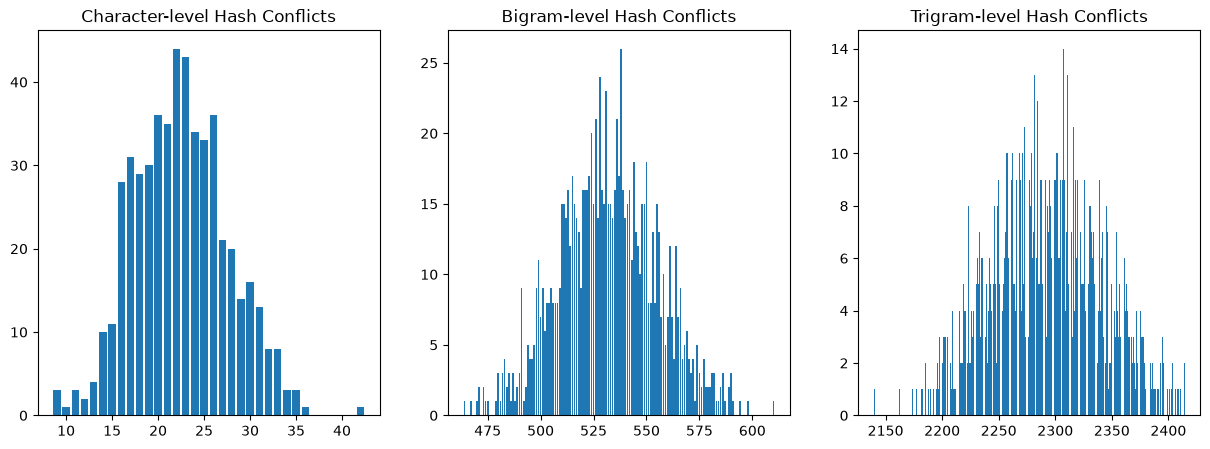

In [11]:
cnt_hc_1 = Counter(map(len, hash_conflicts_chars.values()))
cnt_hc_2 = Counter(map(len, hash_conflicts_bigrams.values()))
cnt_hc_3 = Counter(map(len, hash_conflicts_trigrams.values()))

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

_ = axs[0].bar(cnt_hc_1.keys(), cnt_hc_1.values())
_ = axs[0].set_title('Character-level Hash Conflicts')

_ = axs[1].bar(cnt_hc_2.keys(), cnt_hc_2.values())
_ = axs[1].set_title('Bigram-level Hash Conflicts')

_ = axs[2].bar(cnt_hc_3.keys(), cnt_hc_3.values())
_ = axs[2].set_title('Trigram-level Hash Conflicts')

plt.show()

## 2. Building the classifier with scikit-learn

We load the corpus in a dataframe, indexed by sentence id.

In [12]:
df = pd.read_csv(
    'sentences.csv',
    header=None,
    names=['id', 'language', 'text'],
    sep='\t',
    encoding='utf8'
).set_index('id')

df.head()

,language,text
id,,
1,cmn,我們試試看！
2,cmn,我该去睡觉了。
3,cmn,你在干什麼啊？
4,cmn,這是什麼啊？
5,cmn,今天是６月１８号，也是Muiriel的生日！


#### Feature extraction

We first build a simplified $X$ matrix to understand the CLD3 features. We represent
the nine sentences below with a restricted set of features: the letters _a_, _b_, and
_n_ and the bigrams _an_, _ba_, and _na_. Each row contains the raw counts
`[#a, #b, #n, #an, #ba, #na]`.

In [13]:
example_ngrams = ['a', 'b', 'n', 'an', 'ba', 'na']
test_idx = [1276, 1277, 1280, 1115, 1279, 1441, 337413, 341910, 341938]

df_test = df.loc[test_idx].copy()
for ngram in example_ngrams:
    df_test[ngram] = df_test['text'].str.count(ngram)

df_test[example_ngrams]
df_test['language'].to_list()

,a,b,n,an,ba,na
id,,,,,,
1276,0,0,1,0,0,0
1277,1,0,0,0,0,0
1280,3,1,2,1,0,0
1115,8,0,8,1,0,0
1279,1,0,1,0,0,0
1441,4,1,6,1,0,0
337413,4,0,1,1,0,0
341910,5,2,2,0,1,0
341938,2,0,2,1,0,0


['eng', 'eng', 'eng', 'fra', 'fra', 'fra', 'swe', 'swe', 'swe']

#### Restricting the dataset to a few languages

The corpus is too large to process entirely, so we keep eight languages and at most
`MAX_DOCS` sentences per language. `sample()` uses the NumPy generator we seeded, so
the subset is reproducible.

In [14]:
TARGET_LANGS = ['ara', 'fra', 'cmn', 'jpn', 'kor', 'eng', 'swe', 'dan']
MAX_DOCS = 25000

df = pd.concat([
    df[df['language'] == lang].sample(n=min(len(df[df['language'] == lang]), MAX_DOCS))
    for lang in TARGET_LANGS
], ignore_index=True
)

df.shape
df['language'].value_counts()

(190892, 2)

language
ara    25000
fra    25000
cmn    25000
jpn    25000
eng    25000
swe    25000
dan    25000
kor    15892
Name: count, dtype: int64

#### From $n$-grams to hash codes

`hash_ngrams()` replaces every $n$-gram by its hash code and `calc_rel_freq()` counts
the codes and divides by their total number to obtain relative frequencies, as in
CLD3.

In [15]:
def hash_ngrams(ngrams: list[list[str]], modules: list[int]) -> list[list[int]]:
    '''
    Converts a list of n-gram lists into a list of hash code lists,
    each order reduced by its own module
    '''
    hash_codes = []
    for ngram_list, module in zip(ngrams, modules):
        hash_codes += [[reproducible_hash(gram) % module for gram in ngram_list]]
    return hash_codes

hash_ngrams(all_ngrams("try something."), MAXES)

[[432, 437, 309, 86, 331, 97, 100, 32, 432, 332, 233, 310, 31, 442],
 [6, 765, 224, 203, 557, 176, 590, 711, 527, 757, 919, 57, 685],
 [848, 617, 468, 456, 873, 996, 287, 10, 817, 674, 960, 399]]

In [16]:
def calc_rel_freq(codes: list[int]) -> Counter:
    '''
    Counts the hash codes of one n-gram order and returns their relative frequencies
    '''
    cnt = Counter(codes)
    total = len(codes)
    for key in cnt:
        cnt[key] /= total
    return cnt

[calc_rel_freq(item) for item in hash_ngrams(all_ngrams('try something.'), MAXES)][0]

Counter({432: 0.14285714285714285,
         437: 0.07142857142857142,
         309: 0.07142857142857142,
         86: 0.07142857142857142,
         331: 0.07142857142857142,
         97: 0.07142857142857142,
         100: 0.07142857142857142,
         32: 0.07142857142857142,
         332: 0.07142857142857142,
         233: 0.07142857142857142,
         310: 0.07142857142857142,
         31: 0.07142857142857142,
         442: 0.07142857142857142})

#### Merge dictionaries

The three counters have overlapping numerical keys: the code 432 of a unigram is not
the code 432 of a bigram. We shift the bigram keys by `MAX_CHARS` and the trigram keys
by `MAX_CHARS + MAX_BIGRAMS` before merging them into a single dictionary.

In [17]:
def shift_keys(ngram_freqs: Iterator[Counter], max_shift: list[int]) -> Counter:
    '''
    Merges the frequency dictionaries of the three n-gram orders into a single one,
    shifting the keys of each order by the values of max_shift
    '''
    combined = {}
    for freqs, shift in zip(ngram_freqs, max_shift):
        for code, freq in freqs.items():
            combined[code + shift] = freq
    return Counter(combined)

In [18]:
def build_freq_dict(sentence: str, MAXES: list[int] = MAXES,
                    MAX_SHIFT: list[int] = MAX_SHIFT) -> Counter:
    '''
    Full feature extraction pipeline:
    n-grams -> hash codes -> relative frequencies -> merged dictionary
    '''
    hngrams = hash_ngrams(all_ngrams(sentence), MAXES)
    fhcodes = map(calc_rel_freq, hngrams)
    return shift_keys(fhcodes, MAX_SHIFT)

#### Converting the dataset

We apply the pipeline to every sentence of the reduced dataset. This is the longest
step of the notebook: 190,892 texts, each of them hashed at three orders.

In [19]:
df['features'] = df['text'].apply(build_freq_dict)

df['features'].iloc[0].most_common(5)

[(187, 0.2), (86, 0.16), (134, 0.08), (486, 0.08), (6, 0.08)]

#### Vectorizing $X$

`DictVectorizer` turns the list of dictionaries into a dense matrix where the columns
are the union of all the hash codes. We set `sparse=False` because PyTorch only
accepts dense matrices, and `dtype=np.float32` to halve the memory of a
190,892 $\times$ 2,583 matrix.

In [20]:
X_cat = df['features'].tolist()

vectorizer = DictVectorizer(sparse=False, dtype=np.float32)
X = vectorizer.fit_transform(X_cat)

X.shape, NUM_FEATURES
X[:5]

((190892, 2583), 2583)

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5, 2583), dtype=float32)

#### Vectorizing $\mathbf{y}$

Many machine-learning toolkits require a numerical $\mathbf{y}$ vector. We fit a single
`LabelEncoder` that we will reuse to encode the labels, to decode the predictions, and
to save it with the model. Its classes are sorted alphabetically, so `y_symbols[i]` is
the language of the class `i`.

In [21]:
y_cat = df['language'].to_numpy()

label_encoder = LabelEncoder().fit(y_cat)
y_symbols = label_encoder.classes_.tolist()
y = label_encoder.transform(y_cat)

y_cat[:5]
y_symbols
y[:5]

array(['ara', 'ara', 'ara', 'ara', 'ara'], dtype=object)

['ara', 'cmn', 'dan', 'eng', 'fra', 'jpn', 'kor', 'swe']

array([0, 0, 0, 0, 0])

#### Training the model

We create a multilayer perceptron with a hidden layer of 50 nodes and a relu
activation, the default Adam optimizer and a cross-entropy loss. We split the data
into 80% training and 20% validation, stratified so that both subsets keep the
language balance.

In [22]:
clf = MLPClassifier(hidden_layer_sizes=(50,), activation='relu', max_iter=5, verbose=True)

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=4321,
    stratify=y
)

clf
X_train.shape, X_val.shape

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(50,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",5
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


((152713, 2583), (38179, 2583))

In [23]:
model = clf.fit(X_train, y_train)

Iteration 1, loss = 0.48783195
Iteration 2, loss = 0.05488991
Iteration 3, loss = 0.03506427
Iteration 4, loss = 0.02722793
Iteration 5, loss = 0.02282451


#### Predicting and evaluating

In [24]:
y_val_pred = model.predict(X_val)

y_val[:10]
y_val_pred[:10]
model.score(X_val, y_val)

array([1, 0, 7, 3, 1, 0, 1, 7, 1, 1])

array([1, 0, 7, 3, 1, 0, 1, 7, 1, 1])

0.9910160035621677

In [25]:
print(classification_report(y_val, y_val_pred, target_names=y_symbols))
'Accuracy:', accuracy_score(y_val, y_val_pred)
'Micro F1:', f1_score(y_val, y_val_pred, average='micro')
'Macro F1:', f1_score(y_val, y_val_pred, average='macro')

              precision    recall  f1-score   support

         ara       1.00      1.00      1.00      5000
         cmn       1.00      1.00      1.00      5000
         dan       0.97      0.98      0.98      5000
         eng       0.99      0.99      0.99      5000
         fra       1.00      1.00      1.00      5000
         jpn       1.00      1.00      1.00      5000
         kor       1.00      1.00      1.00      3179
         swe       0.98      0.97      0.98      5000

    accuracy                           0.99     38179
   macro avg       0.99      0.99      0.99     38179
weighted avg       0.99      0.99      0.99     38179



('Accuracy:', 0.9910160035621677)

('Micro F1:', 0.9910160035621677)

('Macro F1:', 0.991299476622977)

The confusion matrix shows which languages are mixed up. Danish and Swedish on the one
hand, Chinese and Japanese on the other hand, share characters and $n$-grams, so they
are the hardest pairs to separate.

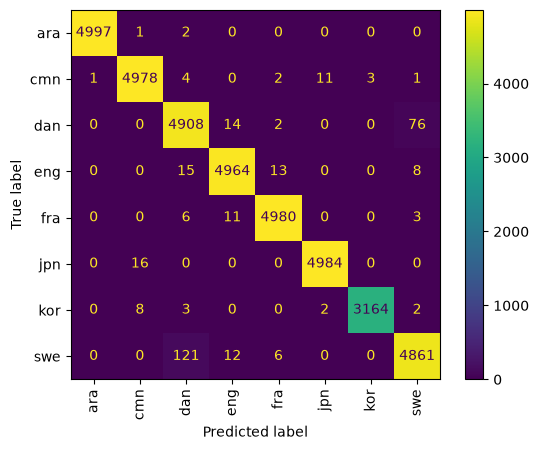

In [26]:
ConfusionMatrixDisplay.from_estimator(
    model,
    X_val,
    y_val,
    display_labels=y_symbols,
    xticks_rotation='vertical'
);

#### Predict the language of a text

We apply the whole pipeline to four new sentences: feature extraction, vectorization
with the *fitted* vectorizer, prediction, and conversion of the class indices back to
language codes.

In [27]:
docs = ["Salut les gars !", "Hejsan grabbar!", "Hello guys!", "Hejsan tjejer!"]

X_test = vectorizer.transform([build_freq_dict(doc) for doc in docs])
pred_idx = model.predict(X_test)
pred_langs = label_encoder.inverse_transform(pred_idx)

pd.DataFrame({
    'text': docs,
    'predicted_language': pred_langs
})

,text,predicted_language
0,Salut les gars !,fra
1,Hejsan grabbar!,swe
2,Hello guys!,eng
3,Hejsan tjejer!,dan


We save the three components of the nano language detector with `joblib` so that we can
reuse them for prediction: the fitted classifier, the vectorizer and the label encoder.

In [28]:
joblib.dump(model, 'nld.joblib')
joblib.dump(vectorizer, 'nld_vectorizer.joblib')
joblib.dump(label_encoder, 'nld_label_encoder.joblib')

['nld.joblib']

['nld_vectorizer.joblib']

['nld_label_encoder.joblib']

## 3. Reimplementing the model with PyTorch

We now recreate the same architecture with PyTorch, where the gradient descent loop is
explicit. With scikit-learn, `fit()` hides the forward pass, the loss, the
backpropagation and the parameter update; here we write them ourselves.

#### The model

`nn.Sequential` with a linear layer of 50 nodes, a relu activation and a linear output
layer. There is no activation on the last layer because `CrossEntropyLoss` applies the
log-softmax internally. We use Adam, the default optimizer of `MLPClassifier`, with its
default learning rate of 0.001.

In [29]:
input_dim = X.shape[1]
nbr_classes = len(TARGET_LANGS)

model = nn.Sequential(
    nn.Linear(input_dim, 50),
    nn.ReLU(),
    nn.Linear(50, nbr_classes)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

model

Sequential(
  (0): Linear(in_features=2583, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=8, bias=True)
)

We convert the matrices to tensors. We keep the `_t` suffix so that the NumPy arrays of
the scikit-learn section stay available for the comparison.

In [30]:
X_train_t = torch.Tensor(X_train)
y_train_t = torch.LongTensor(y_train)

X_val_t = torch.Tensor(X_val)
y_val_t = torch.LongTensor(y_val)

X_test_t = torch.Tensor(X_test)

X_train_t.shape, y_train_t.shape

(torch.Size([152713, 2583]), torch.Size([152713]))

#### The data loader

PyTorch trains on mini-batches. `TensorDataset` pairs the features with the labels and
`DataLoader` slices them into batches of 32, shuffling the training set at every epoch.

In [31]:
train_dataset = TensorDataset(X_train_t, y_train_t)
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True)

val_dataset = TensorDataset(X_val_t, y_val_t)
val_dataloader = DataLoader(val_dataset, batch_size=32)

len(train_dataloader), len(val_dataloader)

(4773, 1194)

#### The training loop

For each epoch we run a training pass and a validation pass. The training pass has the
four steps of the gradient descent: zero the gradients of the previous batch, compute
the logits and the loss, backpropagate, and update the parameters. The validation pass
only computes the loss, inside `torch.no_grad()` and with the model in `eval()` mode.

In [32]:
EPOCHS = 7

ce_train_loss = []
ce_val_loss = []
for epoch in range(EPOCHS):
    # Training pass: one gradient descent step per batch
    _ = model.train()
    batch_train_losses = []
    for X_batch, y_batch in train_dataloader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = loss_fn(outputs, y_batch)
        loss.backward()
        optimizer.step()
        batch_train_losses += [loss.item()]
    ce_train_loss += [sum(batch_train_losses) / len(batch_train_losses)]

    # Validation pass: forward only, no gradient
    _ = model.eval()
    batch_val_losses = []
    with torch.no_grad():
        for X_batch, y_batch in val_dataloader:
            outputs = model(X_batch)
            loss = loss_fn(outputs, y_batch)
            batch_val_losses += [loss.item()]
    ce_val_loss += [sum(batch_val_losses) / len(batch_val_losses)]

    print(f'Epoch {epoch + 1}: train loss {ce_train_loss[-1]:.4f}, '
          f'validation loss {ce_val_loss[-1]:.4f}')

Epoch 1: train loss 0.1585, validation loss 0.0323
Epoch 2: train loss 0.0238, validation loss 0.0262
Epoch 3: train loss 0.0174, validation loss 0.0261
Epoch 4: train loss 0.0142, validation loss 0.0258
Epoch 5: train loss 0.0120, validation loss 0.0267
Epoch 6: train loss 0.0104, validation loss 0.0274
Epoch 7: train loss 0.0092, validation loss 0.0288


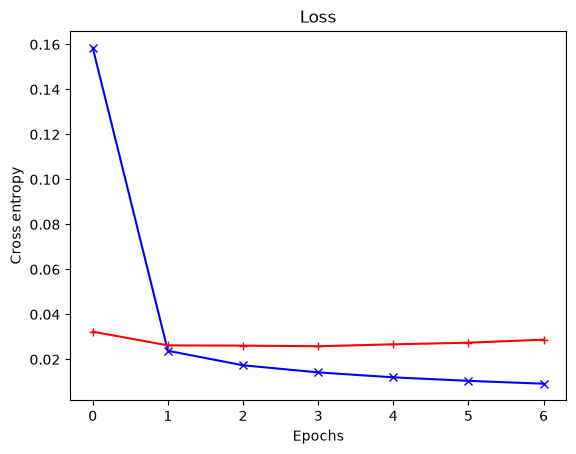

In [33]:
plt.plot(range(len(ce_train_loss)), ce_train_loss, c='b', marker='x')
plt.plot(range(len(ce_val_loss)), ce_val_loss, c='r', marker='+')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Cross entropy')
plt.show();

#### Evaluating the PyTorch model

The network outputs *logits*, one per class. We convert them into probabilities with
`torch.softmax()` and keep the most probable class with `torch.argmax()`.

In [34]:
_ = model.eval()

with torch.no_grad():
    Y_val_pred_logits = model(X_val_t)

Y_val_pred_proba = torch.softmax(Y_val_pred_logits, dim=1)
y_val_pred_t = torch.argmax(Y_val_pred_proba, dim=1)

In [35]:
print(classification_report(y_val_t, y_val_pred_t, target_names=y_symbols))
'Accuracy:', accuracy_score(y_val_t, y_val_pred_t)
'Micro F1:', f1_score(y_val_t, y_val_pred_t, average='micro')
'Macro F1:', f1_score(y_val_t, y_val_pred_t, average='macro')

              precision    recall  f1-score   support

         ara       1.00      1.00      1.00      5000
         cmn       1.00      0.99      0.99      5000
         dan       0.98      0.98      0.98      5000
         eng       0.99      1.00      1.00      5000
         fra       1.00      1.00      1.00      5000
         jpn       1.00      1.00      1.00      5000
         kor       1.00      0.99      1.00      3179
         swe       0.98      0.98      0.98      5000

    accuracy                           0.99     38179
   macro avg       0.99      0.99      0.99     38179
weighted avg       0.99      0.99      0.99     38179



('Accuracy:', 0.992220854396396)

('Micro F1:', 0.992220854396396)

('Macro F1:', 0.9924198980401184)

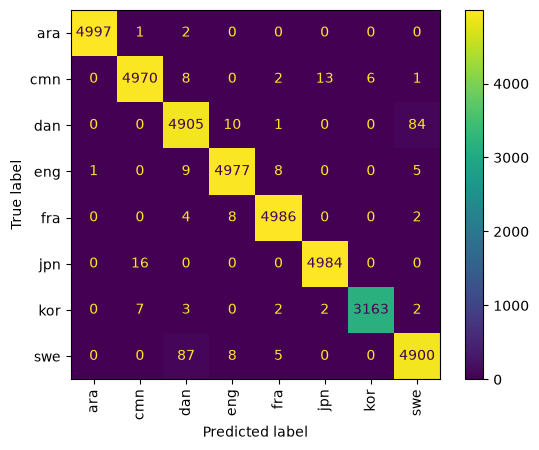

In [36]:
disp = ConfusionMatrixDisplay(
    confusion_matrix(y_val_t, y_val_pred_t),
    display_labels=y_symbols
)
disp.plot(xticks_rotation='vertical')
plt.show();

#### Predict the language of a text

We reuse the `X_test` matrix of the four sentences and compare the predictions of the
two models.

In [37]:
_ = model.eval()

with torch.no_grad():
    Y_test_pred_proba = torch.softmax(model(X_test_t), dim=1)

pred_idx_pytorch = torch.argmax(Y_test_pred_proba, dim=1)
pred_languages_pytorch = label_encoder.inverse_transform(pred_idx_pytorch.numpy())

pd.DataFrame({
    'text': docs,
    'sklearn': pred_langs,
    'pytorch': pred_languages_pytorch
})

,text,sklearn,pytorch
0,Salut les gars !,fra,fra
1,Hejsan grabbar!,swe,swe
2,Hello guys!,eng,eng
3,Hejsan tjejer!,dan,dan


#### Saving the model

We store the weights with `torch.save()` and reload them into a network with the same
architecture to check that the file is usable.

In [38]:
torch.save(model.state_dict(), 'nld.pth')

reloaded = nn.Sequential(
    nn.Linear(input_dim, 50),
    nn.ReLU(),
    nn.Linear(50, nbr_classes)
)
reloaded.load_state_dict(torch.load('nld.pth'))
reloaded.eval();

#### Conclusion

Both models share the same architecture and reach a comparable accuracy. The
scikit-learn version needs a single `fit()` call but hides the optimization, while the
PyTorch version exposes the loss, the optimizer and the mini-batches, which lets us
change the architecture, add regularization or train on a GPU.

Possible improvements, following https://arxiv.org/pdf/2205.03983, are: larger hash
modules to reduce the collisions, word embeddings instead of a flat feature vector, and
more training epochs with early stopping on the validation loss.